# 9.B.1. Признаки из ETS (sktime, AirPassengers)

Модель прогнозирования можно использовать не только как готовый прогноз, но и как **генератор
признаков** для бустинга. Что именно можно взять у ETS:

1. **прогноз** — как обычный признак;
2. **компоненты** — уровень, тренд, сезонность;
3. **остатки** — бустинг учится на том, что ETS не объяснила;
4. **параметры** — α, β, γ как характеристики ряда (подробно — блок 4).

Сквозной вопрос: **что ETS добавляет к тому, что бустинг уже знает из календаря?**

Ряд тот же, что в 9.A.1, чтобы читать результаты поверх знакомых чисел: там лучший бустинг
давал MAPE ≈ 5.4–5.6, наивный — 13.2.

In [1]:
import common  # первым: глушит предупреждения библиотек при импорте

common.quiet()

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from catboost import CatBoostRegressor  # noqa: E402
from sklearn.linear_model import LinearRegression  # noqa: E402
from sktime.forecasting.compose import ForecastingPipeline, TransformedTargetForecaster, YfromX  # noqa: E402
from sktime.forecasting.ets import AutoETS  # noqa: E402
from sktime.forecasting.exp_smoothing import ExponentialSmoothing  # noqa: E402
from sktime.split import temporal_train_test_split  # noqa: E402
from sktime.transformations.series.date import DateTimeFeatures  # noqa: E402
from sktime.transformations.series.detrend import Detrender  # noqa: E402

from common import mape, plot_forecast  # noqa: E402

H = 36
y = common.load_airpassengers()
y_train, y_test = temporal_train_test_split(y, test_size=H)
fh = np.arange(1, H + 1)
month_train, month_test = y_train.index.month.to_numpy(), y_test.index.month.to_numpy()

REGRESSORS = {
    "CatBoost": lambda: CatBoostRegressor(iterations=500, depth=4, random_seed=0, verbose=False),
    "Linear": LinearRegression,
}


def make_ets():
    """Хольт–Винтерс: аддитивный тренд, мультипликативная сезонность."""
    return ExponentialSmoothing(trend="add", seasonal="mul", sp=12)

## 0. ETS сама по себе

Сначала — сама модель: она остаётся в таблице сравнения, сколько бы признаков из неё мы ни
сделали. Для сравнения — `AutoETS`, которая сама выбирает вид тренда и сезонности по AIC.

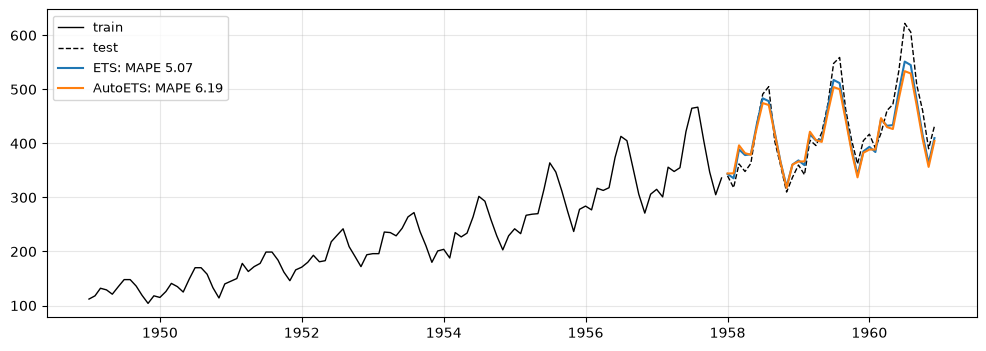

In [2]:
ets = make_ets().fit(y_train)
ets_test = ets.predict(fh=fh)
auto_ets = AutoETS(auto=True, sp=12, n_jobs=1).fit(y_train)

results = {
    "ETS (Хольт–Винтерс)": {"CatBoost": mape(y_test, ets_test), "Linear": np.nan},
    "AutoETS": {"CatBoost": mape(y_test, auto_ets.predict(fh=fh)), "Linear": np.nan},
}
plot_forecast(y_train, y_test, {"ETS": ets_test, "AutoETS": auto_ets.predict(fh=fh)});

ETS уже на уровне лучших бустингов из 9.A.1. Планка высокая: признаки из ETS должны дать
бустингу что-то **сверх** этого, иначе проще взять саму ETS.

Вспомогательная функция: обучить оба регрессора на таблице признаков и записать MAPE.

In [3]:
def fit_eval(name, X_tr, y_tr, X_te, post=lambda p: p):
    """Обучить CatBoost и Linear на (X_tr, y_tr), спрогнозировать X_te; post — обратное преобразование."""
    preds = {}
    for reg_name, reg in REGRESSORS.items():
        model = reg().fit(X_tr, y_tr)
        preds[reg_name] = pd.Series(post(model.predict(X_te)), index=y_test.index)
    results[name] = {reg_name: mape(y_test, p) for reg_name, p in preds.items()}
    return preds

## 1. Прогноз как признак: ловушка in-sample

Самый очевидный способ (так сделано в исходном ноутбуке 9.4): признак `ets` на train — значения,
которые ETS выдаёт на самом train (`fittedvalues`, в sktime — `predict` с отрицательным `fh`),
на test — прогноз ETS на 36 шагов.

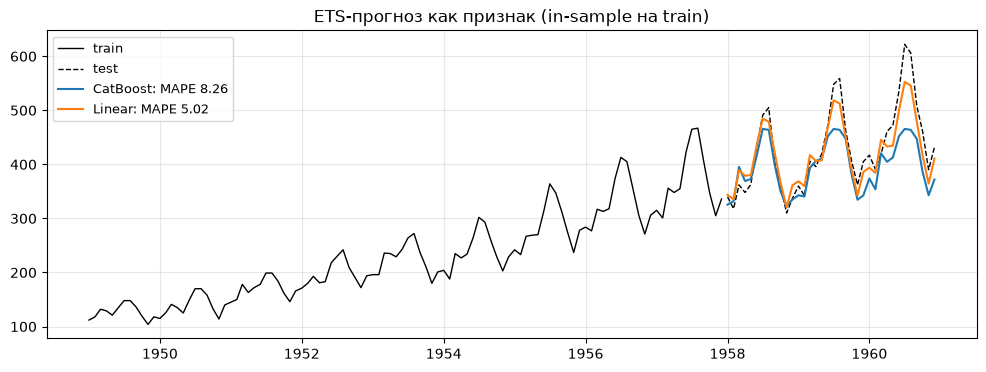

In [4]:
ets_in_sample = ets.predict(fh=-np.arange(len(y_train)))  # fh = 0, -1, …, -107: точки train

X_tr = pd.DataFrame({"month": month_train, "ets": ets_in_sample.to_numpy()})
X_te = pd.DataFrame({"month": month_test, "ets": ets_test.to_numpy()})
preds = fit_eval("прогноз ETS, in-sample", X_tr, y_train.to_numpy(), X_te)
plot_forecast(y_train, y_test, preds, title="ETS-прогноз как признак (in-sample на train)");

In [5]:
importance = REGRESSORS["CatBoost"]().fit(X_tr, y_train).get_feature_importance()
print("важность признаков CatBoost:", dict(zip(X_tr.columns, importance.round(1))))
print(f"ошибка признака на train (in-sample): {mape(y_train, ets_in_sample):.2f}%")
print(f"ошибка признака на test (прогноз):    {mape(y_test, ets_test):.2f}%")
print(f"максимум признака на train: {ets_in_sample.max():.0f}, на test: {ets_test.max():.0f}")
print(f"доля точек теста, где признак выше максимума train: {(ets_test > ets_in_sample.max()).mean():.0%}")

важность признаков CatBoost: {'month': 4.6, 'ets': 95.4}
ошибка признака на train (in-sample): 2.65%
ошибка признака на test (прогноз):    5.07%
максимум признака на train: 468, на test: 551
доля точек теста, где признак выше максимума train: 22%


CatBoost стал **хуже** самой ETS, хотя почти вся важность у признака `ets`. Две причины:

1. **Сдвиг распределения признака** (лонгрид §2.3). На train признак — in-sample значения, они
   точнее (ошибка ≈ 2.6%), чем многошаговый прогноз на тесте (≈ 5.1%). Модель учится доверять
   признаку больше, чем он того заслуживает на тесте.
2. **Деревья не экстраполируют и по признакам**. Прогноз ETS на тесте в 22% точек выше любого
   значения признака на train — для дерева все они попадают в самый правый лист. Это та же
   проблема, что в 9.A.1, только в признаке, а не в target.

Линейная модель здесь ровно повторяет ETS (коэффициент при `ets` ≈ 1) — она ничего не портит,
но и ничего не добавляет.

## 2. Тот же признак, но out-of-sample

Честная версия: признак на train должен быть **прогнозом той же дальности**, что на тесте.
Обучаем ETS на train без последних 36 точек и прогнозируем их — это и есть признак для
обучения бустинга. Платим за честность тем, что бустинг учится всего на 36 строках.

ошибка out-of-sample признака на train: 11.49%


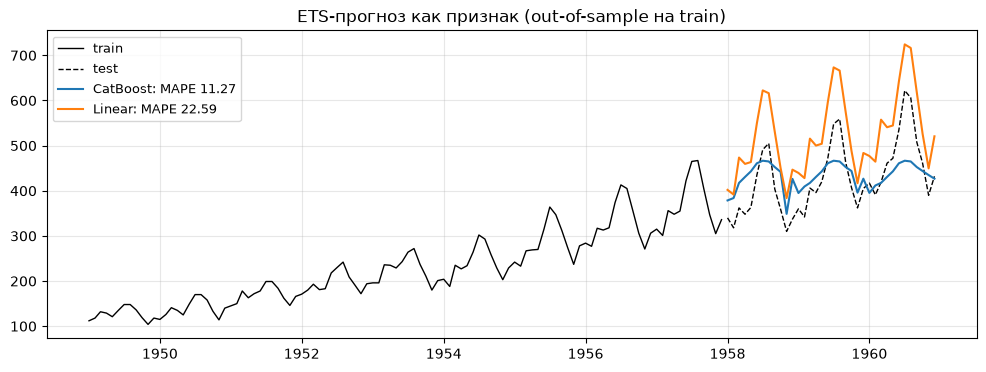

In [6]:
ets_past = make_ets().fit(y_train.iloc[:-H])
ets_oos = ets_past.predict(fh=fh)  # прогноз на последние 36 точек train
print(f"ошибка out-of-sample признака на train: {mape(y_train.iloc[-H:], ets_oos):.2f}%")

X_tr = pd.DataFrame({"month": month_train[-H:], "ets": ets_oos.to_numpy()})
preds = fit_eval("прогноз ETS, out-of-sample", X_tr, y_train.iloc[-H:].to_numpy(), X_te)
plot_forecast(y_train, y_test, preds, title="ETS-прогноз как признак (out-of-sample на train)");

Стало ещё хуже — и это важный урок: **честность признака необходима, но недостаточна**.

- ETS, обученная на 72 точках, прогнозирует заметно хуже (≈ 11.5%), чем на 108 — признак на
  train и на тесте опять разного качества, только теперь в другую сторону;
- бустинг учится на 36 строках — для деревьев это почти ничего;
- экстраполяция по признаку никуда не делась.

На коротком ряде прогноз ETS как признак не работает ни в какой версии. Он полезен, когда у
вспомогательной модели есть информация, которой нет у бустинга (внешние регрессоры), и когда
рядов много, а out-of-sample прогнозы строятся бэктестом по многим точкам отсчёта.

## 3. Компоненты вместо прогноза

Вместо готового прогноза можно отдать бустингу **составные части** ETS: уровень `l`, тренд `b`,
сезонный индекс `s`. Прогноз ETS собирается из них так: `ŷ(t+h) = (l_t + h·b_t) · s_{t+h-12}`.

Компоненты есть в результате statsmodels, который sktime держит внутри (`_fitted_forecaster`).
На train берём сглаженные значения, на тесте — продолжаем по формуле прогноза.

сборка прогноза из компонент совпадает с ETS: True


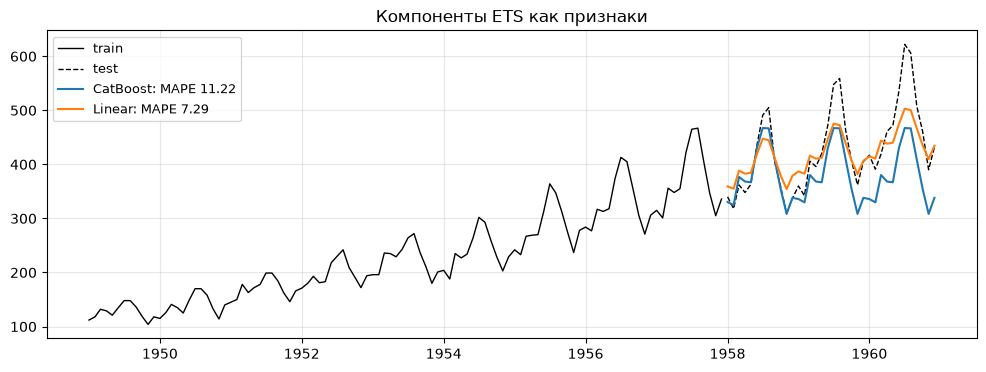

In [7]:
fitted = ets._fitted_forecaster  # statsmodels HoltWintersResults
level, trend, season = (np.asarray(c) for c in (fitted.level, fitted.trend, fitted.season))
h = np.arange(1, H + 1)
components_train = pd.DataFrame({"month": month_train, "level": level, "trend": trend, "season": season})
components_test = pd.DataFrame(
    {"month": month_test, "level": level[-1] + h * trend[-1], "trend": trend[-1], "season": season[-12 + (h - 1) % 12]}
)
recon = components_test["level"] * components_test["season"]
print(f"сборка прогноза из компонент совпадает с ETS: {np.allclose(recon, ets_test)}")

preds = fit_eval("компоненты ETS", components_train, y_train.to_numpy(), components_test)
plot_forecast(y_train, y_test, preds, title="Компоненты ETS как признаки");

Компоненты работают хуже, чем сама ETS, по той же причине, что и прогноз: `level` на тесте
растёт за пределы train, и дерево его «обрезает». Сезонный индекс дублирует признак `month`.

Посмотрим на параметры сглаживания — это и есть вариант 4, «параметры как признаки»:

In [8]:
smoothing = {k: round(float(v), 3) for k, v in fitted.params.items() if k.startswith("smoothing")}
smoothing

{'smoothing_level': 1.0, 'smoothing_trend': 0.0, 'smoothing_seasonal': 0.0}

`α = 1`, `β = γ = 0`: уровень — это просто последнее значение ряда, тренд и сезонность —
постоянные. Отсюда `trend` в таблице выше — константа, бесполезная как признак. Для **одного**
ряда параметры — это просто числа; признаками они становятся, когда рядов много и их нужно
сравнивать между собой (блок 4).

**В ETNA это автоматически не сделать**: `ModelDecomposeTransform` раскладывает ряд моделью на
компоненты, но на будущих датах возвращает `NaN`. Библиотека не спасает от вопроса «чему равен
признак в будущем?» — на него приходится отвечать самому.

## 4. Остатки — единственный работающий вариант

Последний вариант — не признак, а **трансформация target**: ETS снимает уровень, тренд и
сезонность, бустинг учится на отношении `y / ETS` по месяцу, на прогнозе ответ умножается на
прогноз ETS. В sktime это тот же `Detrender`, что в 9.A.1, только внутри не прямая, а ETS.

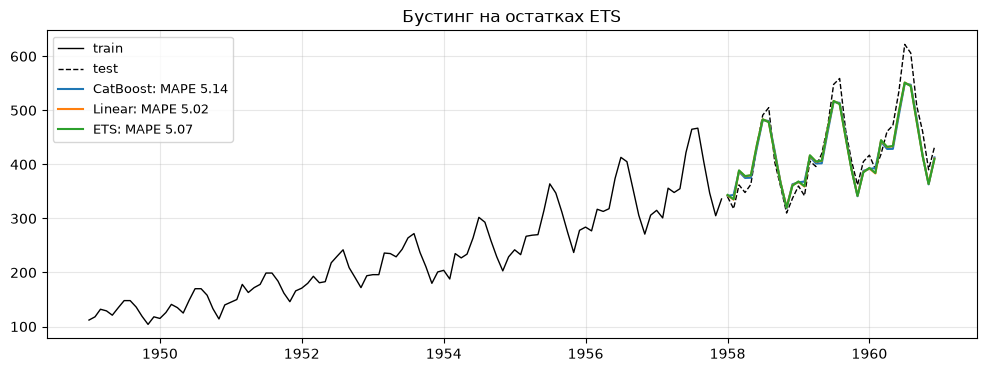

In [9]:
X = pd.DataFrame(index=y.index)
X_train, X_test = X.loc[y_train.index], X.loc[y_test.index]

preds = {}
for reg_name, reg in REGRESSORS.items():
    forecaster = TransformedTargetForecaster(
        [
            Detrender(forecaster=make_ets(), model="multiplicative"),
            ForecastingPipeline([DateTimeFeatures(ts_freq="M", manual_selection=["month_of_year"]), YfromX(reg())]),
        ]
    )
    preds[reg_name] = forecaster.fit(y_train, X=X_train, fh=fh).predict(X=X_test)
results["остатки ETS (Detrender)"] = {reg_name: mape(y_test, p) for reg_name, p in preds.items()}
plot_forecast(y_train, y_test, {**preds, "ETS": ets_test}, title="Бустинг на остатках ETS");

То же самое руками — одна строка, чтобы было видно, что делает `Detrender(model="multiplicative")`:
target — отношение `y / ETS_in-sample`, прогноз — `ETS_test × модель(month)`.

In [10]:
manual = fit_eval(
    "остатки ETS (руками)",
    pd.DataFrame({"month": month_train}),
    (y_train / ets_in_sample).to_numpy(),
    pd.DataFrame({"month": month_test}),
    post=lambda p: p * ets_test.to_numpy(),
)
print(f"руками vs sktime, CatBoost: {mape(y_test, manual['CatBoost']):.2f} vs {mape(y_test, preds['CatBoost']):.2f}")

руками vs sktime, CatBoost: 5.14 vs 5.14


Бустинг на остатках — на уровне самой ETS, и это лучший вариант «ETS + бустинг». Почему
остатки работают, а прогноз-признак нет:

- уровень ряда в будущем даёт ETS, а не дерево — экстраполировать дереву ничего не нужно;
- target бустинга (`y / ETS`) на train и на test одного масштаба — сдвига распределения нет.

Ловушка in-sample здесь тоже есть (остаток на train считается по `fittedvalues`), но она безопасна:
бустинг учит маленькую поправку, а не «насколько доверять признаку».

Выиграть у самой ETS не получилось: на таком чистом ряде ETS уже объясняет почти всё, и бустингу
по одному месяцу добавить нечего. Бустинг на остатках выиграет, когда у него есть признаки, которых
нет у ETS (праздники, промо, погода) — следующий ноутбук.

## 5. Итоги

In [11]:
pd.DataFrame(results).T.round(2)

,CatBoost,Linear
ETS (Хольт–Винтерс),5.07,NaN
AutoETS,6.19,NaN
"прогноз ETS, in-sample",8.26,5.02
"прогноз ETS, out-of-sample",11.27,22.59
компоненты ETS,11.22,7.29
остатки ETS (Detrender),5.14,5.02
остатки ETS (руками),5.14,5.02


| Вариант | Что происходит | Когда полезен |
|---|---|---|
| прогноз, in-sample | признак на train точнее, чем на test; дерево не экстраполирует признак | никогда — это утечка качества |
| прогноз, out-of-sample | честно, но вспомогательная модель на короткой истории хуже, а строк мало | много рядов, бэктест по многим точкам; у модели есть внешняя информация |
| компоненты | та же экстраполяция по уровню; сезонность дублирует календарь | редко; сезонный индекс — для рядов без явного календаря |
| остатки | ETS даёт уровень, бустинг — поправку | почти всегда безопасно; выигрыш — если у бустинга есть свои признаки |
| параметры α, β, γ | характеристика ряда, а не точки | много рядов (блок 4) |

Главный вывод: прежде чем добавлять признак из модели, спросить **«что он добавляет к календарю
и что с ним будет за пределами train?»**. И держать саму модель в таблице сравнения.